# iFome Delivery S.A. — Análise de pedidos

Projeto de análise exploratória com Python e Pandas. As etapas seguem a sequência do desafio original. Os indicadores usam a base sem duplicatas.

## Sprint 1 — Faxina nos Dados

### Task 1 — Importar a base e contar os registros
O arquivo `pedidos.csv` deve estar disponível no ambiente do notebook.

In [2]:
import pandas as pd

df = pd.read_csv("pedidos.csv", sep=";")
print(len(df))

329


### Task 2 — Identificar e remover linhas extras duplicadas

In [3]:
print("Duplicatas extras:", df.duplicated().sum())
df_limpo = df.drop_duplicates().copy()
print("Dimensão após limpeza:", df_limpo.shape)

Duplicatas extras: 9
Dimensão após limpeza: (320, 9)


### Task 3 — Contar avaliações ausentes

In [4]:
df_limpo["avaliacao"].isna().sum()

np.int64(31)

### Task 4 — Contar pedidos cancelados

In [5]:
df_limpo["status"].value_counts()

,count
status,
Entregue,284
Cancelado,36


### Preparação dos tipos de dados para os indicadores
A coluna `valor` usa vírgula decimal no CSV. A coluna `data` usa dia/mês/ano. A conversão é feita **antes** de criar o subconjunto de entregas.

In [6]:
df_limpo["valor"] = pd.to_numeric(
    df_limpo["valor"].astype(str).str.replace(",", ".", regex=False)
)
df_limpo["data"] = pd.to_datetime(df_limpo["data"], format="%d/%m/%Y")

entregues = df_limpo.loc[df_limpo["status"] == "Entregue"].copy()
print(df_limpo[["valor", "data"]].dtypes)
print("Pedidos entregues:", len(entregues))

valor           float64
data     datetime64[ns]
dtype: object
Pedidos entregues: 284


## Sprint 2 — KPIs da Operação

### Task 1 — Ticket médio dos pedidos entregues (inteiro mais próximo)

In [7]:
ticket_medio = entregues["valor"].mean()
print("Ticket médio (R$):", round(ticket_medio))

Ticket médio (R$): 80


### Task 2 — Bairro com mais pedidos

In [8]:
pedidos_por_bairro = df_limpo["bairro"].value_counts()
print(pedidos_por_bairro)
print("Bairro líder:", pedidos_por_bairro.idxmax())

bairro
Centro            90
Jardim América    67
Vila Nova         59
Bela Vista        55
Santa Cruz        49
Name: count, dtype: int64
Bairro líder: Centro


### Task 3 — Tempo médio de entrega (uma casa decimal)

In [9]:
tempo_medio = entregues["tempo_entrega_min"].mean()
print("Tempo médio (min):", round(tempo_medio, 1))

Tempo médio (min): 45.6


### Task 4 — Categoria com maior receita de pedidos entregues

In [10]:
receita_por_categoria = (
    entregues.groupby("categoria")["valor"].sum().sort_values(ascending=False)
)
print(receita_por_categoria)
print("Categoria líder:", receita_por_categoria.idxmax())

categoria
Lanches       5663.95
Pizza         5105.93
Brasileira    4970.90
Japonesa      4216.13
Sobremesas    2815.03
Name: valor, dtype: float64
Categoria líder: Lanches


### Task bônus do CEO — Taxa de cancelamento
A taxa é calculada a partir dos pedidos após a remoção de duplicatas. O valor exato e o arredondamento decimal convencional para uma casa são apresentados.

In [11]:
from decimal import Decimal, ROUND_HALF_UP

# Total de pedidos após a remoção de duplicatas
total_pedidos = len(df_limpo)
total_cancelados = int((df_limpo["status"] == "Cancelado").sum())

# Taxa exata em porcentagem
taxa_cancelamento_exata = Decimal(total_cancelados) * 100 / Decimal(total_pedidos)

# Arredondamento decimal convencional (metade para cima)
taxa_cancelamento = taxa_cancelamento_exata.quantize(
    Decimal("0.1"), rounding=ROUND_HALF_UP
)

print(f"Total de pedidos: {total_pedidos}")
print(f"Pedidos cancelados: {total_cancelados}")
print(f"Taxa exata de cancelamento: {taxa_cancelamento_exata}%")
print(f"Taxa geral de cancelamento (1 casa decimal): {taxa_cancelamento}%")

Total de pedidos: 320
Pedidos cancelados: 36
Taxa exata de cancelamento: 11.25%
Taxa geral de cancelamento (1 casa decimal): 11.3%


## Sprint 3 — Insights para a Diretoria

### Task 1 — Dia da semana com mais pedidos

In [12]:
df_limpo["dia_semana"] = df_limpo["data"].dt.day_name()
pedidos_por_dia = df_limpo["dia_semana"].value_counts()
print(pedidos_por_dia)
print("Dia líder:", pedidos_por_dia.idxmax())

dia_semana
Saturday     71
Sunday       60
Friday       49
Wednesday    44
Thursday     38
Tuesday      32
Monday       26
Name: count, dtype: int64
Dia líder: Saturday


### Task 2 — Avaliação média dos pedidos avaliados (uma casa decimal)
O método `.mean()` ignora avaliações ausentes (`NaN`).

In [13]:
print("Avaliações válidas:", df_limpo["avaliacao"].count())
print("Avaliação média:", round(df_limpo["avaliacao"].mean(), 1))

Avaliações válidas: 289
Avaliação média: 2.9


### Task 3 — Maior pedido entregue (arredondado para inteiro)
`.max()` retorna o valor; `.idxmax()` localiza o índice; `.loc[]` recupera o registro.

In [14]:
maior_valor = entregues["valor"].max()
indice_maior = entregues["valor"].idxmax()
print("Maior pedido (R$ inteiro):", round(maior_valor))
print("Índice:", indice_maior)
display(entregues.loc[[indice_maior]])

Maior pedido (R$ inteiro): 140
Índice: 138


,id_pedido,data,hora,bairro,categoria,valor,tempo_entrega_min,avaliacao,status
138,PED-1006,2026-06-10,22:12,Jardim América,Japonesa,139.91,41,3.0,Entregue


## Sprint 4 — Análises complementares (extras)

Esta seção é independente das 12 tarefas do desafio original. Vamos acrescentar análises e interpretações **uma de cada vez**, após validar as três sprints acima.

### Análise 1 — Tempo médio de entrega por bairro

**Objetivo:** comparar o tempo médio das entregas entre os bairros, considerando apenas pedidos entregues.

In [15]:
tempo_por_bairro = entregues.groupby("bairro")["tempo_entrega_min"].mean()

tempo_por_bairro

,tempo_entrega_min
bairro,
Bela Vista,47.000000
Centro,48.634146
Jardim América,44.758621
Santa Cruz,39.729167
Vila Nova,45.942308


In [16]:
tempo_por_bairro = tempo_por_bairro.sort_values(ascending=False).round(2)

tempo_por_bairro

,tempo_entrega_min
bairro,
Centro,48.63
Bela Vista,47.00
Vila Nova,45.94
Jardim América,44.76
Santa Cruz,39.73


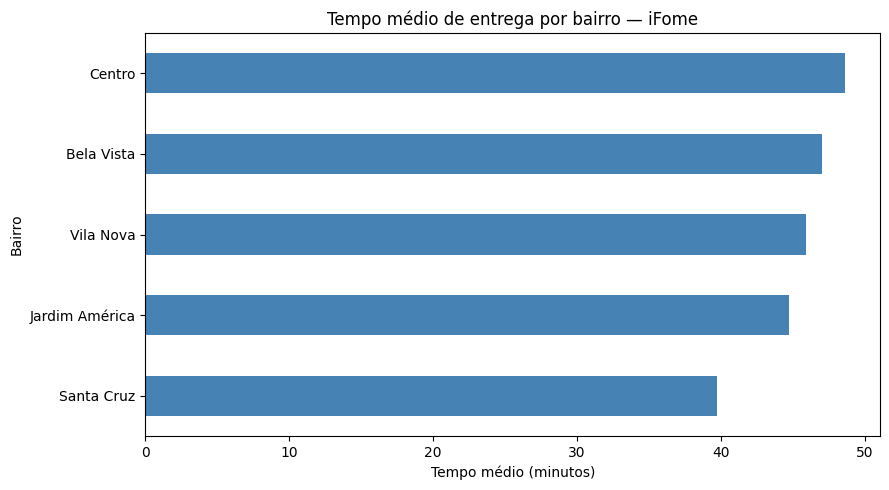

In [17]:
import matplotlib.pyplot as plt

tempo_por_bairro.plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue"
)

plt.title("Tempo médio de entrega por bairro — iFome")
plt.xlabel("Tempo médio (minutos)")
plt.ylabel("Bairro")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Análise dos resultados

A análise dos pedidos entregues identificou diferenças no tempo médio de entrega entre os cinco bairros atendidos pela iFome.

**Principais resultados:**

- **Centro:** maior tempo médio de entrega, com 48,63 minutos.
- **Bela Vista:** segundo maior tempo médio, com 47,00 minutos.
- **Santa Cruz:** menor tempo médio, com 39,73 minutos.

A diferença entre o bairro com maior e menor tempo médio foi de aproximadamente **8,90 minutos**.

**Insight de negócio:**

O Centro merece atenção por apresentar o maior tempo médio de entrega. Recomenda-se investigar fatores como distância percorrida, disponibilidade de entregadores, horários de pico e condições das rotas.

**Limitação da análise:**

Os dados mostram diferenças de desempenho, mas não permitem determinar suas causas. Uma investigação adicional é necessária antes de propor mudanças operacionais.

### Análise 2 — Taxa de cancelamento por categoria

**Objetivo:** identificar quais categorias apresentam as maiores taxas de cancelamento, considerando todos os pedidos sem duplicatas.

In [18]:
pedidos_por_categoria = df_limpo.groupby("categoria")["status"].value_counts()

pedidos_por_categoria

categoria   status   
Brasileira  Entregue     61
            Cancelado     6
Japonesa    Entregue     51
            Cancelado     6
Lanches     Entregue     73
            Cancelado    10
Pizza       Entregue     65
            Cancelado    12
Sobremesas  Entregue     34
            Cancelado     2
Name: count, dtype: int64

In [19]:
taxa_cancelamento_categoria = (
    df_limpo.groupby("categoria")["status"]
    .apply(lambda status: (status == "Cancelado").mean() * 100)
)

taxa_cancelamento_categoria

,status
categoria,
Brasileira,8.955224
Japonesa,10.526316
Lanches,12.048193
Pizza,15.584416
Sobremesas,5.555556


In [20]:
taxa_cancelamento_categoria = (
    taxa_cancelamento_categoria
    .sort_values(ascending=False)
    .round(2)
)

taxa_cancelamento_categoria

,status
categoria,
Pizza,15.58
Lanches,12.05
Japonesa,10.53
Brasileira,8.96
Sobremesas,5.56


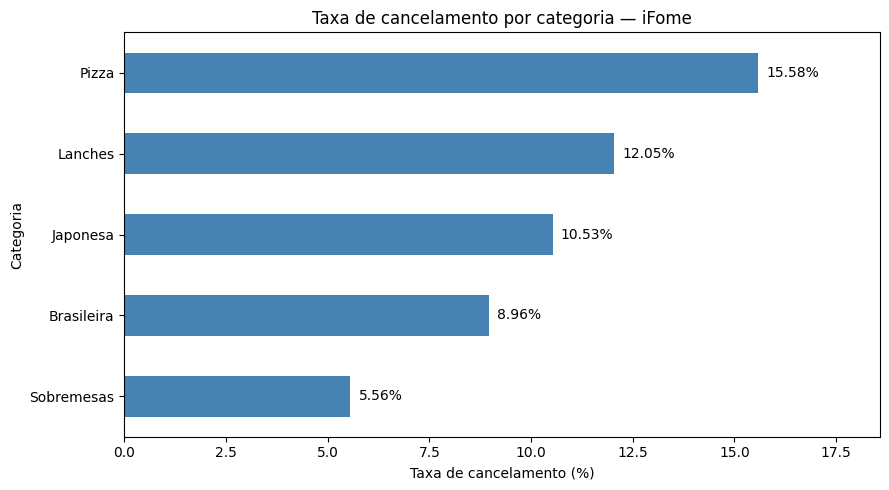

In [21]:
ax = taxa_cancelamento_categoria.plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue"
)

plt.title("Taxa de cancelamento por categoria — iFome")
plt.xlabel("Taxa de cancelamento (%)")
plt.ylabel("Categoria")
plt.gca().invert_yaxis()

for i, valor in enumerate(taxa_cancelamento_categoria):
    ax.text(valor + 0.2, i, f"{valor:.2f}%", va="center")

plt.xlim(0, taxa_cancelamento_categoria.max() + 3)
plt.tight_layout()
plt.show()

### Análise dos resultados — Cancelamentos por categoria

A análise identificou diferenças nas taxas de cancelamento entre as categorias da iFome.

**Principais resultados:**

- **Pizza:** 15,58% — maior taxa de cancelamento.
- **Lanches:** 12,05% — segunda maior taxa.
- **Japonesa:** 10,53%.
- **Brasileira:** 8,96%.
- **Sobremesas:** 5,56% — menor taxa de cancelamento.

A taxa geral de cancelamento da empresa foi de **11,25%**. Pizza e Lanches ficaram acima desse indicador.

**Insight de negócio:**

A categoria Pizza merece prioridade na investigação, pois apresenta uma taxa de cancelamento aproximadamente 4,33 pontos percentuais acima da média geral.

Recomenda-se investigar possíveis fatores, como indisponibilidade de produtos, atrasos no preparo e problemas logísticos.

**Limitações da análise:**

As taxas identificam diferenças entre categorias, mas não explicam as causas dos cancelamentos. Também é necessário considerar a quantidade de pedidos por categoria antes de definir prioridades operacionais.

### Análise 3 — Relação entre tempo de entrega e avaliação

**Objetivo:** investigar se existe associação entre o tempo de entrega e a avaliação dos clientes, considerando apenas pedidos entregues e avaliados.

In [22]:
dados_avaliacao = entregues[
    ["tempo_entrega_min", "avaliacao"]
].dropna().copy()

dados_avaliacao.head()

,tempo_entrega_min,avaliacao
0,24,1.0
1,47,4.0
3,74,3.0
4,16,2.0
5,26,4.0


In [23]:
dados_avaliacao.shape

(256, 2)

In [24]:
correlacao = dados_avaliacao["tempo_entrega_min"].corr(
    dados_avaliacao["avaliacao"]
)

round(correlacao, 3)

np.float64(0.013)

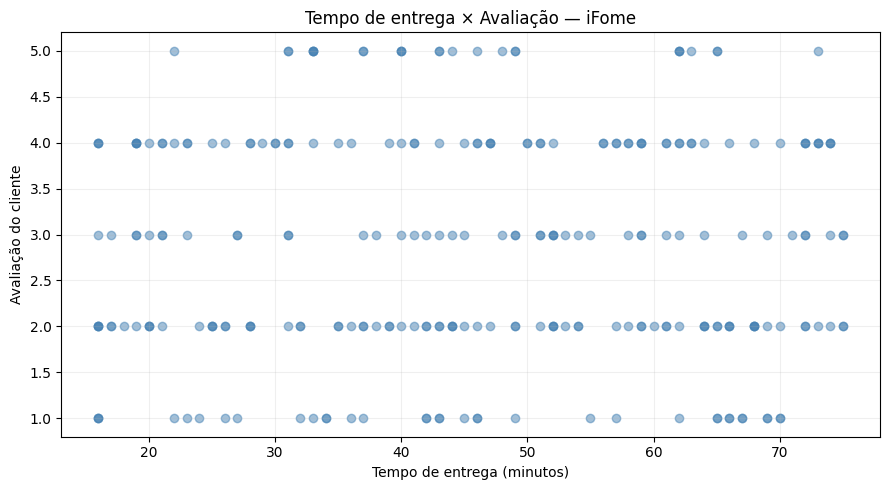

In [25]:
plt.figure(figsize=(9, 5))

plt.scatter(
    dados_avaliacao["tempo_entrega_min"],
    dados_avaliacao["avaliacao"],
    alpha=0.5,
    color="steelblue"
)

plt.title("Tempo de entrega × Avaliação — iFome")
plt.xlabel("Tempo de entrega (minutos)")
plt.ylabel("Avaliação do cliente")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Análise dos resultados — Tempo de entrega e avaliação

Foram analisados 256 pedidos entregues com avaliações disponíveis.

**Principais resultados:**
- Correlação de Pearson: 0,013.
- O resultado indica uma associação linear praticamente nula.
- O gráfico de dispersão não apresenta uma tendência linear evidente entre tempo de entrega e avaliação.

**Insight de negócio:**

O tempo de entrega, isoladamente, não apresentou associação linear relevante com a avaliação dos clientes nesta amostra.

Recomenda-se investigar outras variáveis que possam influenciar a satisfação, como qualidade dos produtos, atendimento e precisão dos pedidos.

**Limitações:**

A ausência de correlação linear não significa que o tempo de entrega não influencie a satisfação. Podem existir relações não lineares ou fatores adicionais não representados nos dados.